# Lesson 2: Count the ways to arrive
## Dice Combinations and Grid Paths

Run in Jupyter or Google Colab with Python 3. No packages or external input files are required. Shift+Enter runs a cell. Run the setup cell first. Predict each result before running code.

Exercise IDs match the worksheet and slides. Small recursive examples are for learning; use iteration for large inputs. Python stops recursion at about 1,000 nested calls by default, so recursive versions are for small inputs only.


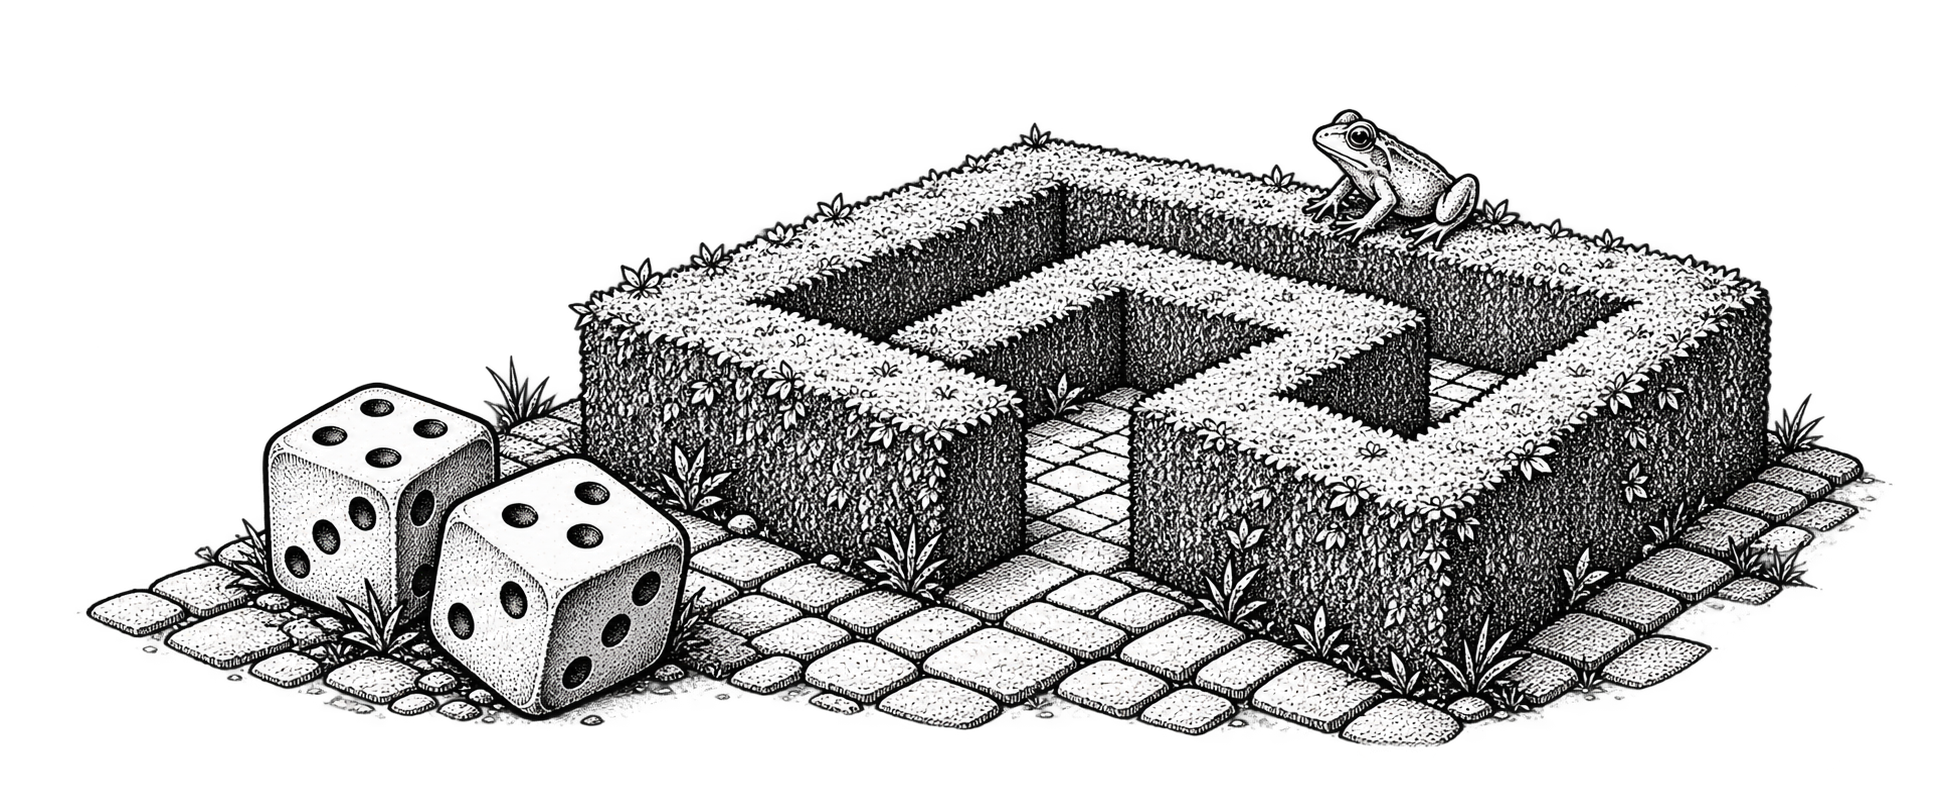

In [ ]:
from functools import lru_cache
MOD = 1_000_000_007
print('Ready. Run cells from top to bottom.')


## The route and the rules

### Our route
Count ordered dice sequences by their final number. Try recursion, save repeated answers, then fill a table. Then see how six reused entries reduce Dice memory from O(n) to O(1), with an optional running sum. Afterwards count grid paths by their final move. The full Dice table remains useful for learning; the buffer is a memory improvement.

### Dice rules · L2-02 to L2-08
Choose any finite ordered sequence of values from 1 to 6. Count sequences whose total is exactly the target n. There is no fixed number of throws and no probability calculation. [1, 2] and [2, 1] are different sequences. For L2-07 only, allow 1, 2 and 3.

### Large counts
The final iterative dice and grid programs return the remainder after dividing the count by 1,000,000,007. Python writes this as `count % 1_000_000_007`. Small examples on these sheets are below that number, so their counts are unchanged. L2-06 explains why taking remainders during the calculation is valid.

### Grid rules · L2-09 to L2-14
The grid has n rows and n columns, numbered from 0. A dot means an open cell; a star means a blocked cell. Start at row 0, column 0. Reach row n - 1, column n - 1 using moves of one cell right or one cell down. A path may never enter a blocked cell.

### Names used in the questions
`ways[total]` stores the number of sequences whose sum is that total. `paths[r][c]` stores the number of paths to row r, column c. The indices identify a total or a cell; the stored values count sequences or paths. A recursive function answers the same question by asking about smaller totals or earlier cells.

## L2-01: Recall: what are we storing?

In staircase, what does ways[4] = 5 mean? In Frog, what does best[4] = 30 mean? Which problem adds and which takes a minimum?

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** There are 5 routes to step 4. The cheapest Frog route to stone 4 costs 30. Staircase adds counts from separate groups; Frog takes the minimum of competing total costs.

Check this before introducing a six-sided die. The list position names the question and the list value answers it. A common error is to describe both entries simply as the value at 4. Ask what the value measures: routes or cost.

If the previous session ended before the iterative Frog trace, use the first ten minutes to finish it. Dice then extends an existing counting idea rather than becoming a separate unexplained formula.

## L2-02: A total of three

List every ordered sequence of numbers from 1 to 6 whose sum is exactly 3. What happens to sequences containing a 4, 5 or 6?

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** The four sequences are [3], [1, 2], [2, 1] and [1, 1, 1]. A sequence containing 4, 5 or 6 already exceeds the target. We count valid sequences rather than simulate random throws.

Present this as a counting puzzle first. A die explains where the permitted numbers come from, but there is no requirement that real random throws reach the target. Only lists with sum exactly 3 are included. Positive numbers cannot undo an overshoot.

Order matters: [1, 2] and [2, 1] are separate outcomes. A sequence may contain repeated numbers and its length is not fixed. Ask students to group the four sequences by final number: two end in 1, one ends in 2 and one ends in 3.

## L2-03: Six possible last numbers

Let ways[total] count ordered sequences of values 1 to 6 whose sum is that total. Explain ways[0] = 1. For target 4, group sequences by their last number and add the earlier counts. Copy your L2-02 count into total 3, then fill totals 5, 6 and 7 in the table.

Total | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7
--- | --- | --- | --- | --- | --- | --- | --- | ---
ways[total] | 1 | 1 | 2 | ? | ? | ? | ? | ?

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** The empty sequence is the one sequence with total 0. For total 4, final numbers 1, 2, 3 and 4 give counts 4 + 2 + 1 + 1 = 8. Totals 5 and 6 give 16 and 32. Total 7 uses totals 6 through 1: 32 + 16 + 8 + 4 + 2 + 1 = 63.

Define total as the target sum before writing an expression using it. If the last die face is face, removing it leaves total - face. Append face to every sequence of that smaller total. Different final faces make disjoint groups, so we add their counts.

Only faces no larger than the total are valid. For total 4, faces 5 and 6 would require negative earlier totals and contribute nothing. The single-element sequence [4] comes from the empty sequence followed by 4. This is why ways[0] must be 1 even though the original problem asks for positive target totals.

**Completed table:**

Total | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7
--- | --- | --- | --- | --- | --- | --- | --- | ---
ways[total] | 1 | 1 | 2 | 4 | 8 | 16 | 32 | 63

## L2-04: Dice: recursion, then caching

Write dice_slow(n) recursively to count ordered sequences of faces 1 to 6 with total n. Trace target 4. Then write dice_cached(n), adding a cache: which input identifies a repeated question? Use the uncached version only on tiny targets. In the cached version, store counts modulo 1,000,000,007.

**Start with:**

```python
def dice_slow(n):
    return None  # Replace with your answer.

def dice_cached(n):
    def count(total):
        return None  # Your helper goes here.
    return count(n)
```

**What each function returns:**
- `dice_slow(n)`: the exact number of ordered dice sequences with total n.
- `dice_cached(n)`: the count for total n, modulo 1,000,000,007.
- `count(total)`: the count for this total, modulo 1,000,000,007.

**Hints:**
- What is the count for total 0?
- Which faces can be the last one when the remaining total is small?
- What input identifies a repeated question, and where must the saved answers live so that every call shares them?


**Your prediction / reasoning:**

Write your explanation here.

**Answer:** Use one cache key per target total. Total 0 contributes 1. For a positive total, try each final face that fits and add the counts for the smaller targets. Faces larger than the remaining total are skipped, so no negative total is ever asked. Target 4 returns 8. A repeated target reads its saved answer instead of branching again.

The slow function calls itself on every legal predecessor. For total 4 it returns 8. It is correct but rapidly repeats smaller totals. The cached version stores answers under integer totals, exactly as staircase stored answers under step numbers.

The decorator used later in Grid Paths is another way to memoize, but here a plain dictionary makes the process explicit. Both styles preserve function results; neither removes deep recursive call chains. Run the slow function only on small totals. For large targets use the iterative program that follows. The notebook includes both versions so students can compare their outputs.

**Recursion depth:** Python stops recursion at about 1,000 nested calls by default, so this recursive version is for small inputs and the small and edge test files only. Use the iterative version for the medium and large files.

In [ ]:
def dice_slow(n):
    if n == 0:
        return 1
    return sum(dice_slow(n - face) for face in range(1, min(6, n) + 1))


**Recursion depth:** Python stops recursion at about 1,000 nested calls by default, so this recursive version is for small inputs and the small and edge test files only. Use the iterative version for the medium and large files.

In [ ]:
def dice_cached(n):
    cache = {0: 1}
    def count(total):
        if total not in cache:
            cache[total] = sum(count(total - face)
                for face in range(1, min(6, total) + 1)) % MOD
        return cache[total]
    return count(n)


In [ ]:
print(dice_slow(4), dice_cached(4))

## L2-05: Dice: fill the totals in order

Write dice_table(n) using a loop. Store in ways[total] the count for that total, modulo 1,000,000,007. Fill totals from 1 upwards. When the loop reaches total 7, which earlier totals does it read? Add their counts and explain the result.

**Start with:**

```python
def dice_table(n):
    return None  # Replace with your answer.
```

**What each function returns:**
- `dice_table(n)`: the number of ordered dice sequences with total n, modulo 1,000,000,007.

**Hints:**
- Which entry is known before the loop?
- For each total, which earlier totals can the last face come from?
- Where do you take the remainder so that stored numbers stay small?


**Your prediction / reasoning:**

Write your explanation here.

**Answer:** Total 7 reads counts for totals 6, 5, 4, 3, 2 and 1. Their sum is 32 + 16 + 8 + 4 + 2 + 1 = 63. Fill totals from 1 upwards, starting with ways[0] = 1.

There is one outer-loop iteration for each target total. The inner loop checks six candidate last faces. For small totals, the guard rejects faces that would require a negative predecessor. In Python, negative list indices silently read from the end, so this guard is part of correctness.

The table has n + 1 entries, including total 0. At most six additions per total gives O(6n), usually written O(n), because six does not grow with n. Memory is O(n). The modulo operation keeps stored numbers bounded; it is explained in the next question. This version is the main classroom solution.

In [ ]:
def dice_table(n):
    ways = [0] * (n + 1)
    ways[0] = 1
    for total in range(1, n + 1):
        for face in range(1, 7):
            if total >= face:
                ways[total] += ways[total - face]
        ways[total] %= MOD
    return ways[n]


In [ ]:
print(dice_table(7))

## L2-06: Why take a remainder?

Modulo 7 means the remainder after division by 7. Compare (12 + 13) % 7 with ((12 % 7) + (13 % 7)) % 7. Why do both calculations give the same remainder? How does this help when dice counts become very large?

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** 12 + 13 = 25, whose remainder is 4. Separately, 12 has remainder 5 and 13 has remainder 6; 5 + 6 = 11 also has remainder 4. Removing whole multiples of 7 does not change a remainder modulo 7. Dice uses the same rule with 1,000,000,007 to keep stored numbers small.

Explain a small modulus before writing the large constant. The remainder is the part left after removing whole groups of the modulus. In Python, 11 % 7 is 4. We are still counting the same sequences; the requested output represents their count by a remainder.

For addition, reducing each part first or reducing their sum at the end gives the same final remainder. Reducing during the computation prevents huge integers from growing throughout the table. The primality of 1,000,000,007 is not needed for this addition-only recurrence. It becomes useful in other algorithms involving modular division, which this lesson does not use.

## L2-07: Your turn: three faces

Write dice_123(n) by adapting dice_table from L2-05 to allow only faces 1, 2 and 3. First fill counts for totals 0 through 5, then write and test your code. Explain the answer for total 5.

**Start with:**

```python
def dice_123(n):
    return None  # Replace with your answer.
```

**What each function returns:**
- `dice_123(n)`: the number of ordered sequences of 1, 2 and 3 with total n, modulo 1,000,000,007.

**Hints:**
- Which part of dice_table depends on the faces allowed?
- Check total 4 by hand before you run the code.


Total | 0 | 1 | 2 | 3 | 4 | 5
--- | --- | --- | --- | --- | --- | ---
ways[total] | 1 | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp;

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** The counts are [1, 1, 2, 4, 7, 13]. Total 5 combines totals 4, 3 and 2, giving 7 + 4 + 2 = 13. Only the allowed-face loop changes.

Ask students to write the allowed faces explicitly rather than changing a magic number without explaining it. The meaning of a state and the base case remain the same. Negative totals remain impossible.

Use total 4 as a useful check. The six-faced version counted [4], but this version must exclude that route, so its answer is 7 instead of 8. The complete exercise solution appears in the teacher guide. The student notebook has a separate function to fill and checks that run after it is implemented.

**Completed table:**

Total | 0 | 1 | 2 | 3 | 4 | 5
--- | --- | --- | --- | --- | --- | ---
ways[total] | 1 | 1 | 2 | 4 | 7 | 13

In [ ]:
def dice_123(n):
    ways = [0] * (n + 1)
    ways[0] = 1
    for total in range(1, n + 1):
        for face in (1, 2, 3):
            if total >= face:
                ways[total] += ways[total - face]
        ways[total] %= MOD
    return ways[n]


In [ ]:
checks = [
    (dice_123(0), 1),
    (dice_123(4), 7),
    (dice_123(5), 13),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All exercise checks passed.')


## L2-08: Extension: six slots instead of a full table (optional extension)

Before total 7, recent is [32, 1, 2, 4, 8, 16] in slots 0 to 5. These store counts for totals [6, 1, 2, 3, 4, 5]. The running sum window is 63. Which slot does 7 % 6 choose, and which old count must be saved before overwriting it? Store the answer for total 7, then prepare the next sum. What should dice_window(7) return? Explain why six slots are enough.

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** 7 % 6 chooses slot 1. Save its old count 1, then store 63. Prepare the next sum: 63 - 1 + 63 = 125, for total 8. Return recent[1] = 63. Only the six preceding counts are needed: reusing their slots reduces memory from O(n) to O(1). Time remains O(n).

The full table keeps a count for every total from 0 to n. To calculate the count for total 7, however, we only read counts for totals 1 to 6. To calculate total 8, we only read totals 2 to 7. Once total 7 is saved, the count for total 1 will never be read again. We can reuse its storage.

Keep six entries in a list named recent. A slot is an index into that list: 0, 1, 2, 3, 4 or 5. A total is the target sum of the dice; a count is the number of ordered sequences for that total. These are three different numbers. The count for total t is stored in slot t % 6. The remainder wraps the chosen index back to 0 after slot 5. The list entries do not move.

Initially recent is [1, 0, 0, 0, 0, 0]. The 1 counts the empty sequence for total 0. The other five entries stand for impossible negative totals, whose counts are 0. These zeros let the same six-entry calculation work when total is smaller than 6. For n = 0 the loop does not run, and slot 0 correctly returns 1.

The circular buffer alone saves memory. Summing six entries still takes a fixed amount of work per total. We can also save their sum in window. Before an iteration, window is the answer we are about to store. After storing that answer, subtract the overwritten count and add the new count to prepare the next sum.

After total 7, recent[1] holds 63, the requested answer. The updated window is 125, ready for total 8. Return recent[n % 6], not window. Assigning an integer to a list entry saves that value; changing window later does not change the saved entry.

Use dice_ring first to separate saving memory from saving additions. Both versions use O(n) time and O(1) extra memory. With n = 1,000,000, recent still has only six entries. MOD keeps stored counts bounded. The 5-minute slot in the timetable is a preview; allow 15-20 minutes as follow-up for the whole trace and code.

**Completed table:**

Slot | 0 | 1 | 2 | 3 | 4 | 5
--- | --- | --- | --- | --- | --- | ---
Total before 7 | 6 | 1 | 2 | 3 | 4 | 5
Count before 7 | 32 | 1 | 2 | 4 | 8 | 16
Total after 7 | 6 | 7 | 2 | 3 | 4 | 5
Count after 7 | 32 | 63 | 2 | 4 | 8 | 16

**Worked explanation: read after attempting L2-08.**

### Why six entries are enough

The full table keeps a count for every total from 0 to n. To calculate the count for total 7, however, we only read counts for totals 1 to 6. To calculate total 8, we only read totals 2 to 7. Once total 7 is saved, the count for total 1 will never be read again. We can reuse its storage.

Keep six entries in a list named recent. A slot is an index into that list: 0, 1, 2, 3, 4 or 5. A total is the target sum of the dice; a count is the number of ordered sequences for that total. These are three different numbers. The count for total t is stored in slot t % 6. The remainder wraps the chosen index back to 0 after slot 5. The list entries do not move.

Initially recent is [1, 0, 0, 0, 0, 0]. The 1 counts the empty sequence for total 0. The other five entries stand for impossible negative totals, whose counts are 0. These zeros let the same six-entry calculation work when total is smaller than 6. For n = 0 the loop does not run, and slot 0 correctly returns 1.

Slot | 0 | 1 | 2 | 3 | 4 | 5
--- | --- | --- | --- | --- | --- | ---
Total before 7 | 6 | 1 | 2 | 3 | 4 | 5
Count before 7 | 32 | 1 | 2 | 4 | 8 | 16
Total after 7 | 6 | 7 | 2 | 3 | 4 | 5
Count after 7 | 32 | 63 | 2 | 4 | 8 | 16

The circular buffer alone saves memory. Summing six entries still takes a fixed amount of work per total. We can also save their sum in window. Before an iteration, window is the answer we are about to store. After storing that answer, subtract the overwritten count and add the new count to prepare the next sum.

At total 7: save old count 1, store 63, then prepare 63 - 1 + 63 = 125.

After total 7, recent[1] holds 63, the requested answer. The updated window is 125, ready for total 8. Return recent[n % 6], not window. Assigning an integer to a list entry saves that value; changing window later does not change the saved entry.

`dice_ring` sums six values per iteration; `dice_window` updates their saved sum. Both take O(n) time and O(1) extra memory. Here `window` is the same running sum as `sum_contributions` in the circular-buffer version.

In [ ]:
def dice_ring(n):
    recent = [0] * 6
    recent[0] = 1
    for total in range(1, n + 1):
        answer = sum(recent) % MOD
        recent[total % 6] = answer
    return recent[n % 6]


In [ ]:
def dice_window(n):
    recent = [0] * 6
    recent[0] = 1
    window = 1
    for total in range(1, n + 1):
        slot = total % 6
        oldest = recent[slot]
        recent[slot] = window
        window = (window - oldest + recent[slot]) % MOD
    return recent[n % 6]


In [ ]:
print(dice_ring(7), dice_window(7))
print(dice_ring(8), dice_window(8))

## L2-09: Grid Paths: draw before coding

In a 3 by 3 grid, a dot is open and a star is blocked. Start at the top left and finish at the bottom right. Move only one cell right or down. The centre cell is blocked. Draw or list every legal route; how many are there?

Row / column | 0 | 1 | 2
--- | --- | --- | ---
0 | . | . | .
1 | . | \* | .
2 | . | . | .

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** Two routes remain: right, right, down, down; and down, down, right, right. Every other route would visit the blocked centre square.

Draw the grid with rows numbered from 0 at the top and columns numbered from 0 at the left. A cell has two coordinates: row r and column c. Neither coordinate is a path count. A dot means open and a star means blocked.

There are no diagonal moves, no left moves and no upward moves. Start and finish are cells, not positions outside the grid. If either is blocked, there are zero valid routes. The same last-move reasoning used for dice now considers the previous cell rather than the previous total.

## L2-10: A grid cell receives two counts

Rows and columns are numbered from 0. Let paths[r][c] count routes from the top-left cell to row r, column c. From which cells can the last move arrive? Fill the count table for the 3 by 3 grid with its centre blocked, writing 0 for the blocked cell.

Row / column | 0 | 1 | 2
--- | --- | --- | ---
0 | 1 | ? | ?
1 | ? | ? | ?
2 | ? | ? | ?

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** An open cell receives paths from above and from its left. The count table is rows [1, 1, 1], [1, 0, 1], [1, 1, 2]. A blocked cell contributes zero.

Every route to an open non-start cell has a final move from above or from the left. These groups do not overlap because their last edges differ. Add their counts. Outside the grid there are no routes, so a missing neighbour contributes zero.

The open starting cell has one route: being there before moving. Check for a blocked cell before applying this start rule, otherwise a blocked starting square incorrectly receives one path. Filling rows top to bottom and columns left to right ensures that both needed neighbours are ready.

**Completed table:**

Row / column | 0 | 1 | 2
--- | --- | --- | ---
0 | 1 | 1 | 1
1 | 1 | 0 | 1
2 | 1 | 1 | 2

## L2-11: Grid recursion identifies a cell

Write grid_cached(rows) with a cached recursive helper count(r, c). The helper returns the number of legal paths from the top-left cell to cell (r, c). Ask about the cells above and to the left. State the answers for an outside cell, a blocked cell and an open starting cell. Why do the calls stop?

**Start with:**

```python
def grid_cached(rows):
    n = len(rows)
    def count(r, c):
        return None  # Your helper goes here.
    return count(n - 1, n - 1)
```

**What each function returns:**
- `grid_cached(rows)`: the number of legal paths from top-left to bottom-right, modulo 1,000,000,007.
- `count(r, c)`: the number of legal paths from top-left to cell (r, c), modulo 1,000,000,007.

**Hints:**
- Which cells can you answer directly: outside the grid, blocked, and the start?
- From which two cells can the last move into (r, c) come?


**Your prediction / reasoning:**

Write your explanation here.

**Answer:** The key is the pair (r, c). Each call goes one row up or one column left, so r + c decreases. Outside cells and blocked cells return 0; the open starting cell returns 1.

The slow version asks the two smaller questions directly. The cached version uses @lru_cache(None), which stores the result for each pair of arguments. The decorator belongs to the local count function so a different grid receives a fresh cache.

The bounds check must precede reading rows[r][c]. Python evaluates or from left to right and stops when it finds a true part, so negative coordinates return before indexing. The recursion can still become deep on large grids. There are O(n squared) distinct cells in an n by n grid, but the longest chain is proportional to the number of rows plus columns.

**Recursion depth:** Python stops recursion at about 1,000 nested calls by default, so this recursive version is for small inputs and the small and edge test files only. Use the iterative version for the medium and large files.

In [ ]:
def grid_slow(rows):
    n = len(rows)
    def count(r, c):
        if r < 0 or c < 0 or rows[r][c] == '*':
            return 0
        if r == 0 and c == 0:
            return 1
        return count(r - 1, c) + count(r, c - 1)
    return count(n - 1, n - 1)


**Recursion depth:** Python stops recursion at about 1,000 nested calls by default, so this recursive version is for small inputs and the small and edge test files only. Use the iterative version for the medium and large files.

In [ ]:
def grid_cached(rows):
    n = len(rows)
    @lru_cache(None)
    def count(r, c):
        if r < 0 or c < 0 or rows[r][c] == '*':
            return 0
        if r == 0 and c == 0:
            return 1
        return (count(r - 1, c) + count(r, c - 1)) % MOD
    return count(n - 1, n - 1)


In [ ]:
print(grid_slow(['...', '.*.', '...']), grid_cached(['...', '.*.', '...']))

## L2-12: Grid iteration and independent rows

Write grid_table(rows) using loops over rows and columns. The grid has n rows and n columns. Fill paths[r][c], taking counts modulo 1,000,000,007. Why does [[0] * n for _ in range(n)] create independent rows? For n = 2, show what goes wrong with [[0] * n] * n when one cell changes.

**Start with:**

```python
def grid_table(rows):
    return None  # Replace with your answer.
```

**What each function returns:**
- `grid_table(rows)`: the number of legal paths from top-left to bottom-right, modulo 1,000,000,007.

**Hints:**
- Create the table so that every row is a separate list.
- In which order must you visit the cells so that the cells above and to the left are already filled?
- What does a blocked cell store?


**Your prediction / reasoning:**

Write your explanation here.

**Answer:** A comprehension builds a new list for each row. With bad = [[0] * 2] * 2, setting bad[0][0] = 1 makes both rows [1, 0], because they share one list. Separate rows keep the second row unchanged. Fill each open cell from above and left, then return the bottom-right count.

Explain paths[r][c] in two accesses: paths[r] selects a row list, and [c] selects a count in that row. The underscore in the comprehension is simply a loop variable whose value we do not need.

For each cell, handle a blocked cell first, then the start, then add valid predecessor counts. The row and column guards avoid reading negative indices. There are n squared cells and constant work per cell, so time and memory are O(n squared). Keeping one row is an extension; the full table is easier to draw, inspect and connect to the recurrence.

In [ ]:
def grid_table(rows):
    n = len(rows)
    paths = [[0] * n for _ in range(n)]
    for r in range(n):
        for c in range(n):
            if rows[r][c] == '*':
                continue
            if r == 0 and c == 0:
                paths[r][c] = 1
            else:
                above = paths[r - 1][c] if r > 0 else 0
                left = paths[r][c - 1] if c > 0 else 0
                paths[r][c] = (above + left) % MOD
    return paths[-1][-1]


In [ ]:
print(grid_table(['...', '.*.', '...']))

## L2-13: Your turn: test the boundaries

Test your grid_table(rows) from L2-12. First predict the answers for a single open cell, a single blocked cell, an open 2 by 2 grid, and a 3 by 3 grid with the centre blocked. Then run your function and compare.

Test grid | Your prediction | Program output
--- | --- | ---
['.']  (one open cell) | &nbsp; | &nbsp;
['\*']  (one blocked cell) | &nbsp; | &nbsp;
['..', '..']  (open 2 by 2) | &nbsp; | &nbsp;
['...', '.\*.', '...']  (centre blocked) | &nbsp; | &nbsp;

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** The answers are 1, 0, 2 and 2 respectively. An open start has one empty route. A blocked start has none. In the 2 by 2 grid the routes are right-down and down-right.

These small tests target different rules. The one-cell cases reveal the order of the blocked-cell and start checks. The 2 by 2 case checks both predecessor directions. The blocked-centre case checks that blocked cells interrupt routes without preventing unrelated paths.

Ask students to draw the count table before executing. If a test fails, compare the first incorrect cell rather than staring at the final output. This is also a good place to revisit the difference between a board square and the count stored for that square.

**Completed table:**

Test grid | Your prediction | Program output
--- | --- | ---
['.']  (one open cell) | 1 | 1
['\*']  (one blocked cell) | 0 | 0
['..', '..']  (open 2 by 2) | 2 | 2
['...', '.\*.', '...']  (centre blocked) | 2 | 2

In [ ]:
def grid_table(rows):
    n = len(rows)
    paths = [[0] * n for _ in range(n)]
    for r in range(n):
        for c in range(n):
            if rows[r][c] == '*':
                continue
            if r == 0 and c == 0:
                paths[r][c] = 1
            else:
                above = paths[r - 1][c] if r > 0 else 0
                left = paths[r][c - 1] if c > 0 else 0
                paths[r][c] = (above + left) % MOD
    return paths[-1][-1]


In [ ]:
checks = [
    (grid_table(['.']), 1),
    (grid_table(['*']), 0),
    (grid_table(['..', '..']), 2),
    (grid_table(['...', '.*.', '...']), 2),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All exercise checks passed.')


## L2-14: The shared counting idea

In Dice, group completed sequences by their last number. In Grid Paths, group completed paths by their last move. Why can we add the group counts in each problem? Explain why no completed sequence or path belongs to two of these groups.

**Your prediction / reasoning:**

Write your explanation here.

**Answer:** Both describe the last move of a completed object. Each valid sequence or path belongs to exactly one last-move group. Add those groups when they are exhaustive and do not overlap.

The important shared idea is not the number of dimensions. It is the meaning of the answer and a way to divide all valid objects into separate groups. Dice groups sequences by their last face. Grid Paths groups paths by their final edge.

Ask students to identify the start answer, impossible states and computation order in both problems. An explanation that says only add previous values is incomplete: they should be able to say what those values count and why no object is counted twice.

## Original problem sources
- [Dice Combinations - CSES 1633](https://cses.fi/problemset/task/1633)
- [Grid Paths - CSES 1638](https://cses.fi/problemset/task/1638)